In [2]:

from google.colab import files

uploaded = files.upload()


Saving CH30_synthetic_datasets_1000_rows_each.zip to CH30_synthetic_datasets_1000_rows_each.zip


In [3]:

# Round 1 - Data Understanding, Preparation & EDA

import zipfile
import pandas as pd
import os

# Extract the ZIP file
zip_path = "/content/CH30_synthetic_datasets_1000_rows_each.zip"
extract_path = "/content/CH30_data"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

# Load all five datasets
bookings = pd.read_csv(f"{extract_path}/bookings.csv")
facilities = pd.read_csv(f"{extract_path}/facilities.csv")
occupancy = pd.read_csv(f"{extract_path}/occupancy.csv")
calendar = pd.read_csv(f"{extract_path}/calendar.csv")
maintenance = pd.read_csv(f"{extract_path}/maintenance.csv")

datasets = {
    "Bookings": bookings,
    "Facilities": facilities,
    "Occupancy": occupancy,
    "Calendar": calendar,
    "Maintenance": maintenance
}

# Inspect each dataset
for name, df in datasets.items():
    print(f"\n{'=' * 40}")
    print(f"DATASET: {name}")
    print("=" * 40)

    print("Shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nFirst 5 rows:")
    print(df.head())



DATASET: Bookings
Shape: (1000, 5)

Column names:
['facility', 'date', 'start', 'end', 'purpose']

Data types:
facility    object
date        object
start       object
end         object
purpose     object
dtype: object

Missing values:
facility    0
date        0
start       0
end         0
purpose     0
dtype: int64

Duplicate rows: 25

First 5 rows:
   facility        date  start    end    purpose
0  C-LAB-05  2026-07-24  09:00  10:00       Exam
1  E-LIB-09  2026-07-10  10:00  11:00    Lecture
2  G-CLA-16  2026-07-20  14:00  15:00  Practical
3  E-LIB-08  2026-08-31  12:00  14:00  Practical
4  D-LAB-07  2026-07-10  11:00  13:00      Study

DATASET: Facilities
Shape: (20, 4)

Column names:
['facility', 'type', 'capacity', 'block']

Data types:
facility    object
type        object
capacity     int64
block       object
dtype: object

Missing values:
facility    0
type        0
capacity    0
block       0
dtype: int64

Duplicate rows: 0

First 5 rows:
   facility        type  capacity 

In [4]:
# Clean missing values, duplicates and facility names

import pandas as pd
import numpy as np

# Preserve the original datasets
bookings_clean = bookings.copy()
facilities_clean = facilities.copy()
occupancy_clean = occupancy.copy()
calendar_clean = calendar.copy()
maintenance_clean = maintenance.copy()

# 1. Standardize facility names
def standardize_name(series):
    return (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(r"\s+", "-", regex=True)
    )

for df in [
    bookings_clean, facilities_clean,
    occupancy_clean, maintenance_clean
]:
    df["facility"] = standardize_name(df["facility"])

# 2. Remove confirmed duplicate bookings
bookings_before = len(bookings_clean)
bookings_clean = bookings_clean.drop_duplicates().reset_index(drop=True)

print("Duplicate bookings removed:",
      bookings_before - len(bookings_clean))

# 3. Fix the calendar's 'None' interpretation
calendar_clean["event"] = (
    calendar_clean["event"]
    .fillna("No Event")
    .replace("None", "No Event")
)

# Remove exact duplicate calendar records
calendar_before = len(calendar_clean)
calendar_clean = calendar_clean.drop_duplicates().reset_index(drop=True)

print("Exact calendar duplicates removed:",
      calendar_before - len(calendar_clean))

# 4. Handle missing occupancy readings
# Impute using the median count for the same facility.
# If a facility has no valid readings, use the overall median.
overall_median = occupancy_clean["count"].median()
facility_medians = occupancy_clean.groupby("facility")["count"].median()

missing_before = occupancy_clean["count"].isna().sum()

occupancy_clean["count"] = occupancy_clean["count"].fillna(
    occupancy_clean["facility"].map(facility_medians)
).fillna(overall_median)

print("Missing occupancy readings handled:", missing_before)

# 5. Handle incomplete maintenance records
# Preserve unknown values rather than inventing maintenance details.
maintenance_clean["issue"] = (
    maintenance_clean["issue"].fillna("Unknown")
)
# Keep missing downtime as NaN until verified.
# Missing downtime must not automatically be treated as zero.

# 6. Convert dates and timestamps to proper data types
bookings_clean["date"] = pd.to_datetime(
    bookings_clean["date"], errors="coerce"
)
occupancy_clean["timestamp"] = pd.to_datetime(
    occupancy_clean["timestamp"], errors="coerce"
)
calendar_clean["date"] = pd.to_datetime(
    calendar_clean["date"], errors="coerce"
)

# 7. Check occupancy against facility capacity
capacity_map = facilities_clean.set_index("facility")["capacity"]

occupancy_clean["capacity"] = occupancy_clean["facility"].map(
    capacity_map
)

occupancy_clean["over_capacity"] = (
    occupancy_clean["count"] > occupancy_clean["capacity"]
)

print("Occupancy readings above capacity:",
      occupancy_clean["over_capacity"].sum())
print("Facility names without a capacity match:",
      occupancy_clean["capacity"].isna().sum())





Duplicate bookings removed: 25
Exact calendar duplicates removed: 481
Missing occupancy readings handled: 54
Occupancy readings above capacity: 29
Facility names without a capacity match: 0


Top 5 Most Booked Facilities:
facility
E-LIB-08    108
A-CLA-01     86
A-CLA-02     81
C-LAB-05     69
F-SEM-10     62
Name: count, dtype: Int64


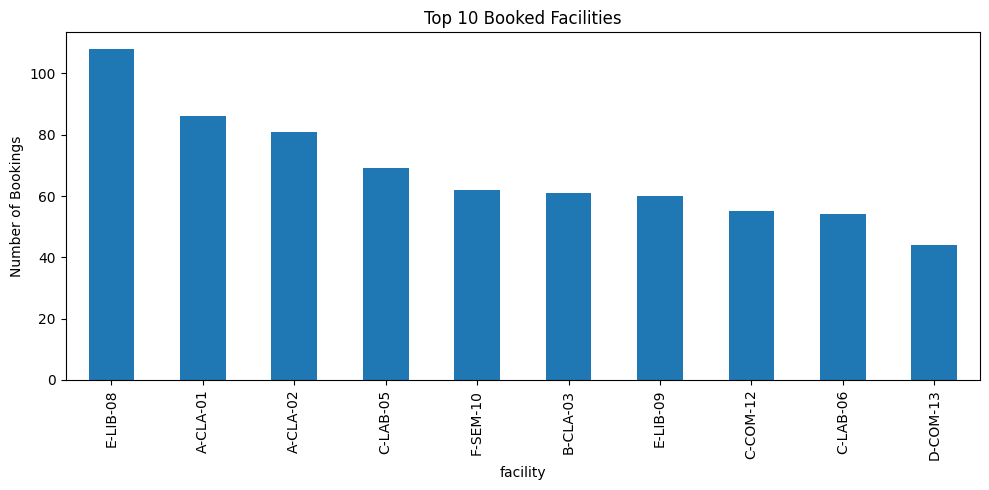


Average Occupancy by Hour:
hour
8     21.971429
9     22.341463
10    33.344538
11    30.342657
12    23.128319
13    27.378947
14    37.600000
15    31.899281
16    20.794872
17    19.318182
18    24.872340
Name: count, dtype: float64


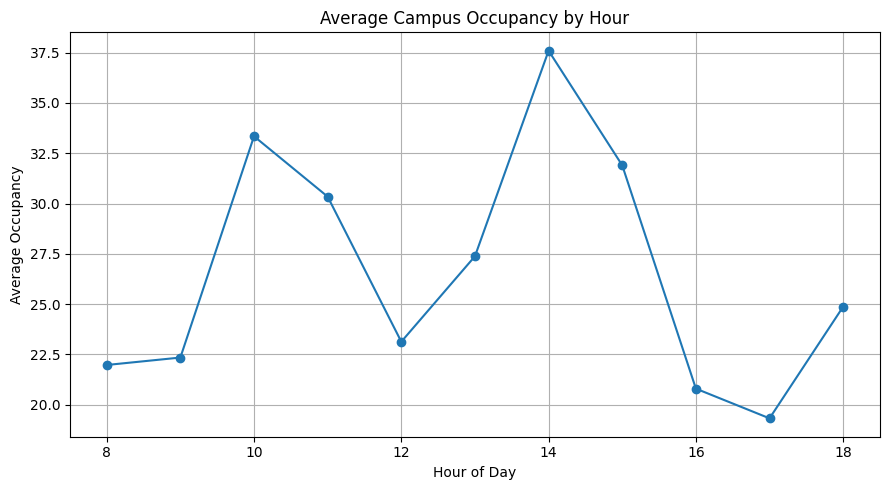


Top 5 Facilities by Average Occupancy:
facility
F-AUD-11    102.166667
F-SEM-10     59.450980
E-LIB-08     52.482759
G-COM-15     40.274510
B-SEM-20     39.068182
Name: count, dtype: float64


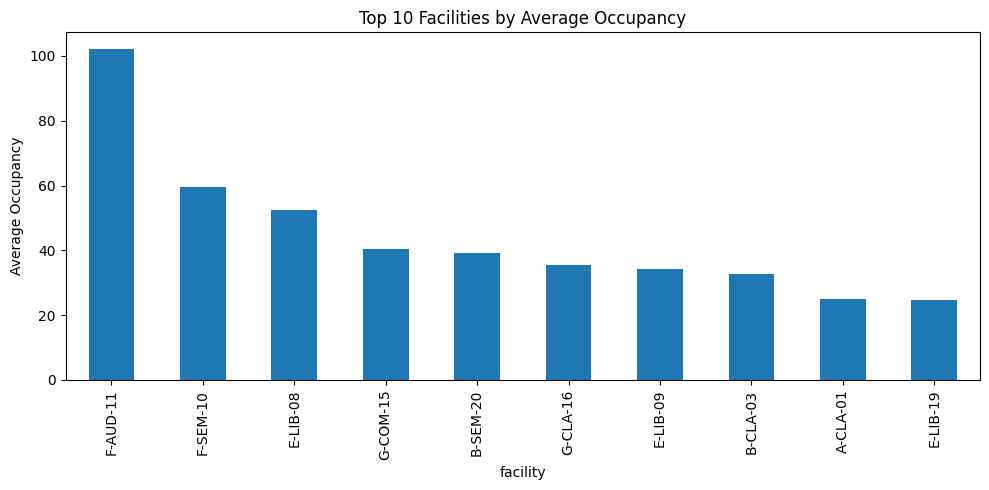


Facility Utilization (%):
          capacity  average_occupancy  utilization_percent
facility                                                  
G-CLA-16        70              35.40                50.57
E-STU-14        20               9.60                48.02
A-CLA-02        40              19.11                47.76
D-LAB-17        25              11.66                46.62
E-LIB-08       120              52.48                43.74
A-MEE-18        15               6.51                43.40
E-LIB-09        80              34.14                42.68
B-CLA-04        50              21.31                42.63
A-CLA-01        60              25.12                41.87
E-LIB-19        60              24.67                41.12
B-CLA-03        80              32.64                40.80
G-COM-15       100              40.27                40.27
F-SEM-10       150              59.45                39.63
B-SEM-20       100              39.07                39.07
C-COM-12        50           

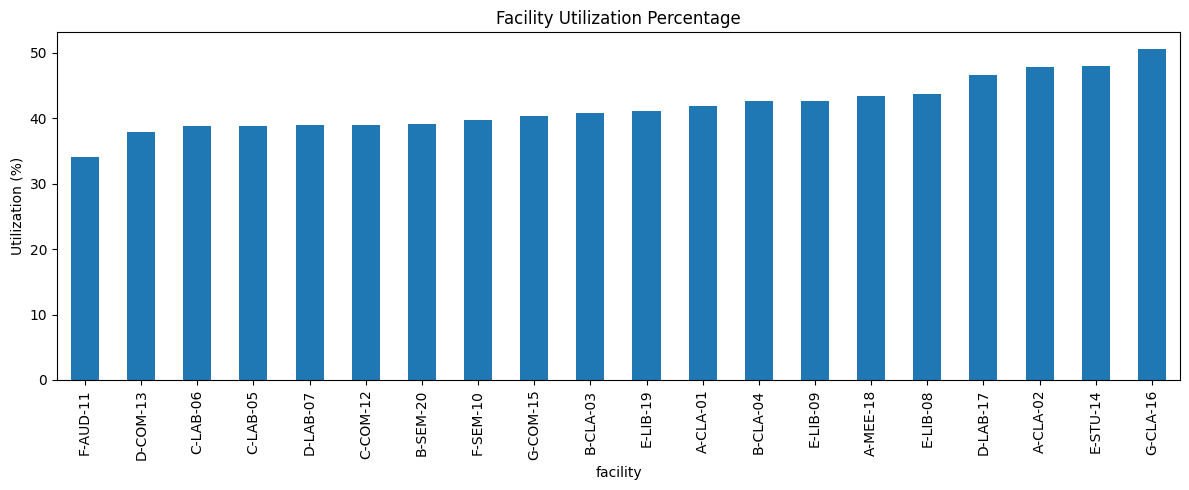

In [5]:
# Exploratory Data Analysis (EDA)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Most frequently booked facilities
booking_counts = bookings_clean["facility"].value_counts()

print("Top 5 Most Booked Facilities:")
print(booking_counts.head(5))

booking_counts.head(10).plot(
    kind="bar", figsize=(10, 5), title="Top 10 Booked Facilities"
)
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()


# 2. Occupancy by hour
occupancy_clean["hour"] = occupancy_clean["timestamp"].dt.hour

hourly_occupancy = occupancy_clean.groupby("hour")["count"].mean()

print("\nAverage Occupancy by Hour:")
print(hourly_occupancy)

hourly_occupancy.plot(
    kind="line", marker="o", figsize=(9, 5),
    title="Average Campus Occupancy by Hour"
)
plt.xlabel("Hour of Day")
plt.ylabel("Average Occupancy")
plt.grid(True)
plt.tight_layout()
plt.show()


# 3. Average occupancy by facility
facility_occupancy = (
    occupancy_clean.groupby("facility")["count"]
    .mean()
    .sort_values(ascending=False)
)

print("\nTop 5 Facilities by Average Occupancy:")
print(facility_occupancy.head(5))

facility_occupancy.head(10).plot(
    kind="bar", figsize=(10, 5),
    title="Top 10 Facilities by Average Occupancy"
)
plt.ylabel("Average Occupancy")
plt.tight_layout()
plt.show()


# 4. Compare average occupancy with capacity
capacity_comparison = facilities_clean.set_index("facility")[
    ["capacity"]
].join(facility_occupancy.rename("average_occupancy"))

capacity_comparison["utilization_percent"] = (
    capacity_comparison["average_occupancy"]
    / capacity_comparison["capacity"] * 100
)

print("\nFacility Utilization (%):")
print(capacity_comparison.sort_values(
    "utilization_percent", ascending=False
).round(2))

capacity_comparison["utilization_percent"].sort_values().plot(
    kind="bar", figsize=(12, 5),
    title="Facility Utilization Percentage"
)
plt.ylabel("Utilization (%)")
plt.tight_layout()
plt.show()


In [7]:
# Identify two important EDA findings.

# Finding 1: Most frequently booked facility
top_facility = bookings_clean["facility"].value_counts().idxmax()
top_bookings = bookings_clean["facility"].value_counts().max()

print("EDA Finding 1")
print(f"Most booked facility: {top_facility}")
print(f"Total bookings: {top_bookings}")


# Finding 2: Peak occupancy hour
occupancy_clean["hour"] = occupancy_clean["timestamp"].dt.hour

hourly_avg = occupancy_clean.groupby("hour")["count"].mean()
peak_hour = hourly_avg.idxmax()
peak_occupancy = hourly_avg.max()

print("\nEDA Finding 2")
print(f"Peak occupancy hour: {peak_hour}:00")
print(f"Average occupancy: {peak_occupancy:.2f}")


EDA Finding 1
Most booked facility: E-LIB-08
Total bookings: 108

EDA Finding 2
Peak occupancy hour: 14:00
Average occupancy: 37.60


In [9]:
# Round 2 – Feature Engineering & Machine Learning
# Step 1 — Create the ML dataset

import pandas as pd
import numpy as np

# 1. Start with occupancy readings
ml_data = occupancy_clean.copy()

# Remove columns previously added during preprocessing
cols_to_remove = [
    "capacity", "type", "block", "over_capacity",
    "date", "hour", "day_of_week",
    "working day", "event", "exam period"
]
ml_data = ml_data.drop(
    columns=cols_to_remove, errors="ignore"
)

# 2. Extract date and time features
ml_data["timestamp"] = pd.to_datetime(ml_data["timestamp"])
ml_data["date"] = ml_data["timestamp"].dt.normalize()
ml_data["hour"] = ml_data["timestamp"].dt.hour
ml_data["day_of_week"] = ml_data["timestamp"].dt.dayofweek

# 3. Add facility details
ml_data = ml_data.merge(
    facilities_clean[["facility", "type", "capacity", "block"]],
    on="facility",
    how="left",
    validate="many_to_one"
)

# 4. Prepare calendar features
cal = calendar_clean.copy()
cal["date"] = pd.to_datetime(cal["date"]).dt.normalize()

cal = cal.groupby("date").agg(
    **{
        "working day": ("working day", "max"),
        "exam period": ("exam period", "max"),
        "event": ("event", lambda s:
            s[s != "No Event"].mode().iloc[0]
            if not s[s != "No Event"].mode().empty
            else "No Event"
        )
    }
).reset_index()

# 5. Merge calendar data
ml_data = ml_data.merge(
    cal,
    on="date",
    how="left",
    validate="many_to_one"
)

# 6. Remove invalid target or unmatched facility rows
ml_data = ml_data.dropna(
    subset=["count", "capacity", "type", "block"]
).copy()

ml_data = ml_data[ml_data["count"] >= 0].copy()

# 7. Define input features and target
features = [
    "facility", "type", "block", "capacity",
    "hour", "day_of_week", "working day",
    "event", "exam period"
]

X = ml_data[features].copy()
y = ml_data["count"].astype(float)

X["working day"] = X["working day"].fillna(False)
X["exam period"] = X["exam period"].fillna(False)
X["event"] = X["event"].fillna("No Event")

print("ML dataset created successfully!")
print("Dataset shape:", ml_data.shape)
print("Input feature count:", len(features))
print("Target variable: count (occupancy)")
print("\nTarget summary:")
print(y.describe())


ML dataset created successfully!
Dataset shape: (1000, 12)
Input feature count: 9
Target variable: count (occupancy)

Target summary:
count    1000.000000
mean       28.145500
std        28.147884
min         0.000000
25%        10.000000
50%        20.000000
75%        36.000000
max       308.000000
Name: count, dtype: float64


In [10]:
#Step 2: Train and evaluate the Machine Learning model.

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Define categorical and numerical features
categorical_features = ["facility", "type", "block", "event"]

numerical_features = [
    "capacity", "hour", "day_of_week",
    "working day", "exam period"
]

# Preprocess categorical variables
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("num", "passthrough", numerical_features)
])

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2
    ))
])

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model: Random Forest Regressor")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")


Model: Random Forest Regressor
Training records: 800
Testing records: 200
MAE: 14.68
RMSE: 26.29
R2 Score: 0.4030


In [12]:
# Model Performance: Accuracy, F1-score, RMSE or another appropriate metric, with the actual obtained value.

# Select one test record
sample = X_test.iloc[[0]]

# Predict occupancy
predicted_occupancy = model.predict(sample)[0]
actual_occupancy = y_test.iloc[0]

print("Sample Facility:", sample["facility"].iloc[0])
print("Actual Occupancy:", round(actual_occupancy, 2))
print("Predicted Occupancy:", round(predicted_occupancy, 2))
print("Absolute Error:",
      round(abs(actual_occupancy - predicted_occupancy), 2))

print("FINAL MODEL PERFORMANCE")
print("-----------------------")
print("Algorithm: Random Forest Regressor")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")


Sample Facility: D-COM-13
Actual Occupancy: 24.0
Predicted Occupancy: 14.42
Absolute Error: 9.58
FINAL MODEL PERFORMANCE
-----------------------
Algorithm: Random Forest Regressor
Training samples: 800
Testing samples: 200
MAE: 14.68
RMSE: 26.29
R² Score: 0.4030
